# ML-13 Capstone: End-to-End Machine Learning Project
One notebook, the whole Chapter 2 arc: framing, data, cleaning, scaling, pipelines, model selection, tuning, the evaluation protocol, and launch. Every number below is computed live in this notebook.

*The 4,128-row test set is sealed in cell 2 and never touched again.*

In [1]:
# Setup: imports (run this cell first in a fresh kernel)
import numpy as np, pandas as pd, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from scipy.stats import randint
plt.rcParams.update({'figure.facecolor':'white','axes.facecolor':'white','font.size':11})
housing = pd.read_csv('/tmp/ml7_datasets/datasets/housing/housing.csv')
print(housing.shape)
housing.head(3)

(20640, 10)
   longitude  latitude  ...  median_house_value  ocean_proximity
0    -122.23     37.88  ...            452600.0         NEAR BAY
1    -122.22     37.86  ...            358500.0         NEAR BAY
2    -122.24     37.85  ...            352100.0         NEAR BAY

[3 rows x 10 columns]


In [2]:
# Frame the problem: predict median_house_value (regression, supervised).
# Stratified split on income category — the test set is locked away here.
housing['income_cat'] = pd.cut(housing['median_income'],
                              bins=[0., 1.5, 3.0, 4.5, 6., np.inf],
                              labels=[1, 2, 3, 4, 5])
strat_train_set, strat_test_set = train_test_split(
    housing, test_size=0.2, stratify=housing['income_cat'], random_state=42)
print('train rows:', strat_train_set.shape[0])
print('test rows (SEALED):', strat_test_set.shape[0])
housing = strat_train_set.drop('income_cat', axis=1)
housing_labels = housing['median_house_value'].copy()
housing = housing.drop('median_house_value', axis=1)

train rows: 16512
test rows (SEALED): 4128


In [3]:
housing.info()
print()
print('missing values per column:')
print(housing.isnull().sum()[housing.isnull().sum() > 0])

<class 'pandas.DataFrame'>
Index: 16512 entries, 13096 to 19888
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           16512 non-null  float64
 1   latitude            16512 non-null  float64
 2   housing_median_age  16512 non-null  float64
 3   total_rooms         16512 non-null  float64
 4   total_bedrooms      16344 non-null  float64
 5   population          16512 non-null  float64
 6   households          16512 non-null  float64
 7   median_income       16512 non-null  float64
 8   ocean_proximity     16512 non-null  str    
dtypes: float64(8), str(1)
memory usage: 1.3 MB

missing values per column:
total_bedrooms    168
dtype: int64


In [4]:
housing.describe().T[['count','mean','std','min','50%','max']].round(2)

                      count     mean      std     min      50%       max
longitude           16512.0  -119.57     2.00 -124.35  -118.51   -114.49
latitude            16512.0    35.64     2.13   32.55    34.26     41.95
housing_median_age  16512.0    28.58    12.59    1.00    29.00     52.00
total_rooms         16512.0  2639.40  2185.29    2.00  2125.00  39320.00
total_bedrooms      16344.0   538.95   423.86    1.00   434.00   6210.00
population          16512.0  1425.51  1094.80    3.00  1167.00  16305.00
households          16512.0   499.99   382.87    1.00   408.00   5358.00
median_income       16512.0     3.87     1.89    0.50     3.54     15.00


## 1. Explore: first look at the data

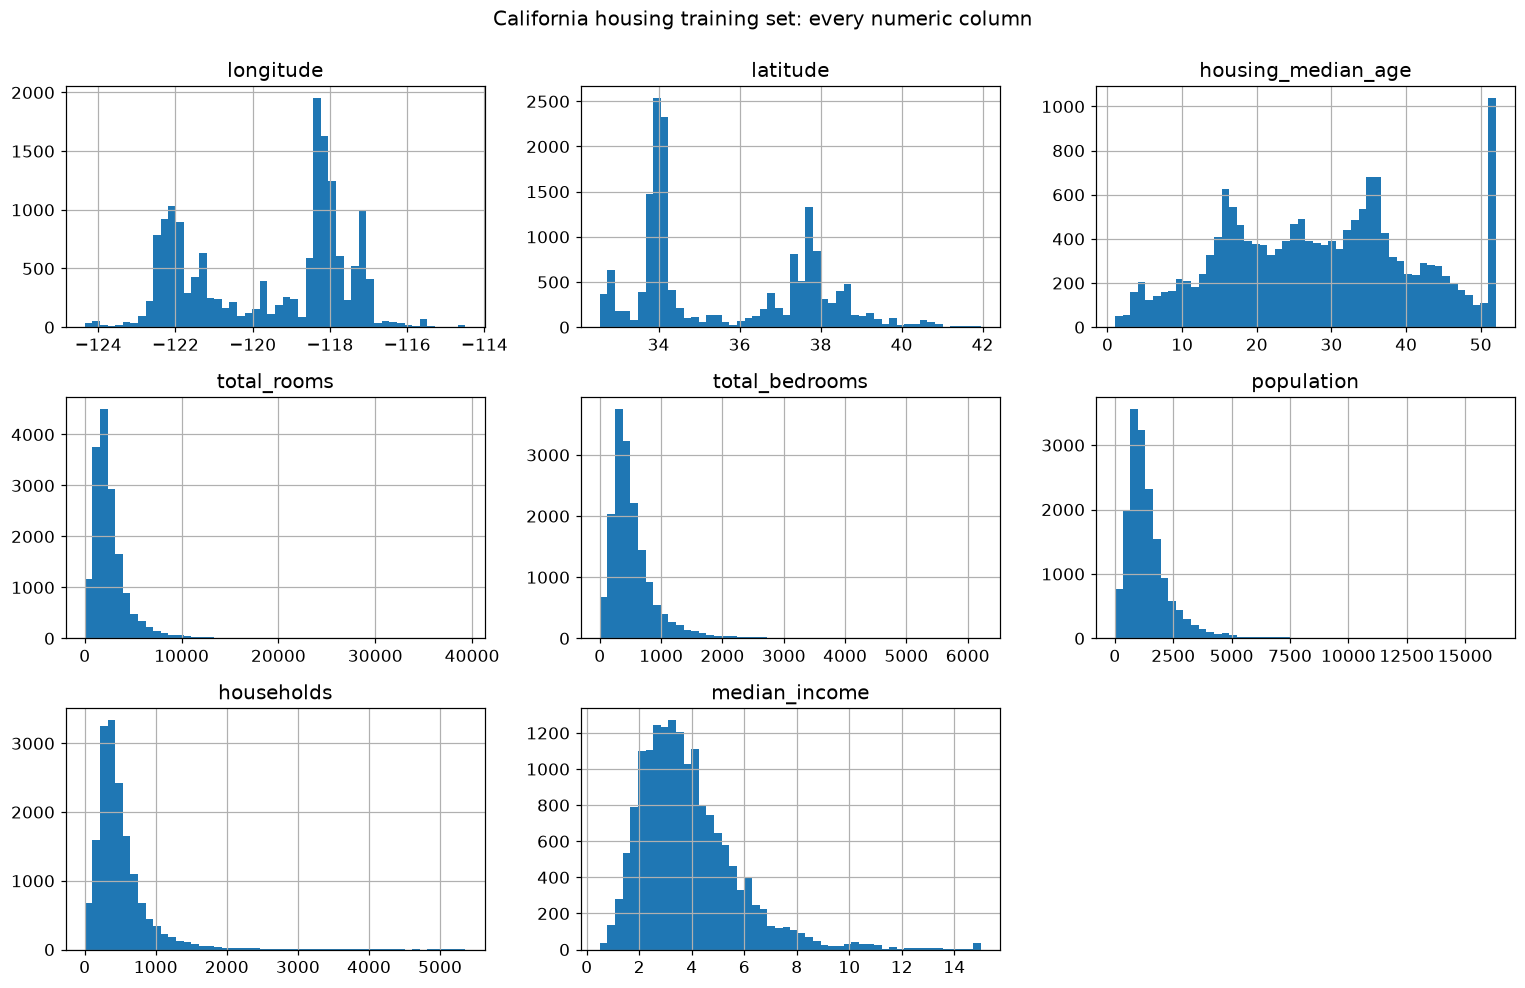

In [5]:
housing.hist(bins=50, figsize=(14, 9))
plt.suptitle('California housing training set: every numeric column', y=0.995)
plt.tight_layout()

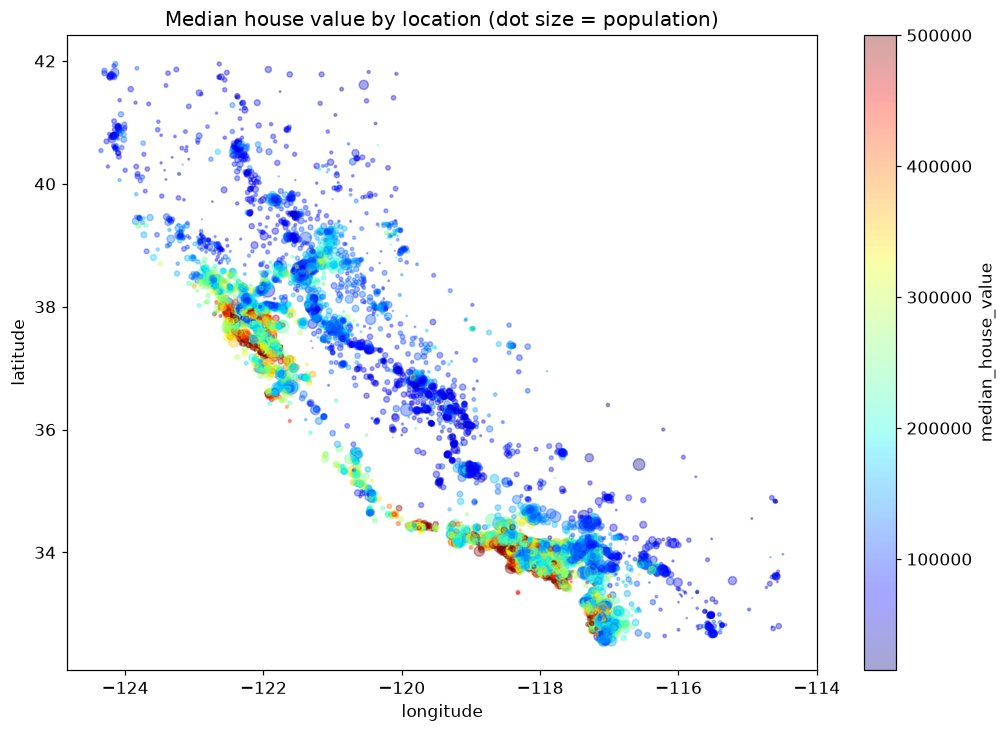

In [6]:
# Where are the expensive districts? Price-colored map of California.
fig, ax = plt.subplots(figsize=(11, 7.5))
sc = ax.scatter(housing['longitude'], housing['latitude'], alpha=0.35,
                s=housing['population']/120, c=housing_labels, cmap='jet')
plt.colorbar(sc, ax=ax, label='median_house_value')
ax.set_xlabel('longitude'); ax.set_ylabel('latitude')
ax.set_title('Median house value by location (dot size = population)')

In [7]:
corr = housing.assign(median_house_value=housing_labels).corr(numeric_only=True)
print('correlation with median_house_value:')
print(corr['median_house_value'].sort_values(ascending=False).round(3))

correlation with median_house_value:
median_house_value    1.000
median_income         0.688
total_rooms           0.137
housing_median_age    0.102
households            0.071
total_bedrooms        0.055
population           -0.020
longitude            -0.051
latitude             -0.140
Name: median_house_value, dtype: float64


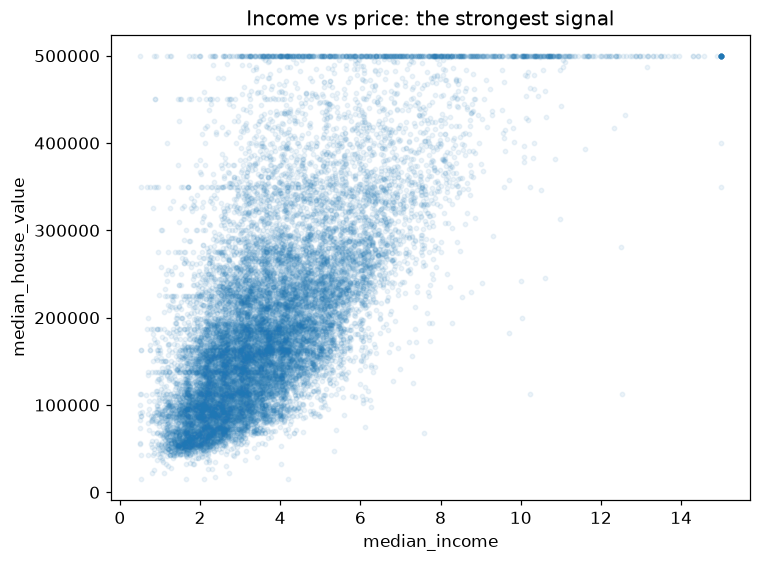

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.scatter(housing['median_income'], housing_labels, alpha=0.08, s=8)
ax.set_xlabel('median_income'); ax.set_ylabel('median_house_value')
ax.set_title('Income vs price: the strongest signal')

## 2. Clean: impute the missing, encode the words (lesson 9)

In [9]:
imp = SimpleImputer(strategy='median')
num_cols = housing.select_dtypes(include=[np.number]).columns.tolist()
imp.fit(housing[num_cols])
print('median learned for total_bedrooms:', imp.statistics_[num_cols.index('total_bedrooms')])

median learned for total_bedrooms: 434.0


In [10]:
print('ocean_proximity categories:')
print(housing['ocean_proximity'].value_counts())
enc = OneHotEncoder()
oh = enc.fit_transform(housing[['ocean_proximity']])
print('one-hot shape:', oh.shape)
print('categories:', list(enc.categories_[0]))

ocean_proximity categories:
ocean_proximity
<1H OCEAN     7274
INLAND        5301
NEAR OCEAN    2089
NEAR BAY      1846
ISLAND           2
Name: count, dtype: int64
one-hot shape: (16512, 5)
categories: ['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN']


## 3. Scale + custom features (lesson 10)

In [11]:
sc = StandardScaler()
sc.fit(housing[['median_income']])
print('mean_:', sc.mean_.round(4), ' scale_:', sc.scale_.round(4))
print('income 3.0 ->', round(float(sc.transform([[3.0]])[0,0]), 2))
print('income 15.0001 ->', round(float(sc.transform([[15.0001]])[0,0]), 2))

mean_: [3.8704]  scale_: [1.8919]
income 3.0 -> -0.46
income 15.0001 -> 5.88


In [12]:
class CombinedAttributesAdder(BaseEstimator, TransformerMixin):
    def __init__(self, add_bedrooms_per_room=True):
        self.add_bedrooms_per_room = add_bedrooms_per_room
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        rooms_per_household = X[:, 3] / X[:, 6]
        population_per_household = X[:, 5] / X[:, 6]
        if self.add_bedrooms_per_room:
            bedrooms_per_room = X[:, 4] / X[:, 3]
            return np.c_[X, rooms_per_household, population_per_household, bedrooms_per_room]
        return np.c_[X, rooms_per_household, population_per_household]

adder = CombinedAttributesAdder()
X_num = imp.transform(housing[num_cols])
X_plus = adder.transform(X_num)
print('numeric in:', X_num.shape, '-> with engineered features:', X_plus.shape)
print('row 0 rooms/household: %.2f  pop/household: %.2f  bedrooms/room: %.3f' % tuple(X_plus[0, -3:]))

numeric in: (16512, 8) -> with engineered features: (16512, 11)
row 0 rooms/household: 3.21  pop/household: 1.52  bedrooms/room: 0.336


## 4. One object to prepare everything (lesson 11)

In [13]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('attribs_adder', CombinedAttributesAdder()),
    ('std_scaler', StandardScaler()),
])
full_pipeline = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', OneHotEncoder(), ['ocean_proximity']),
])
housing_prepared = full_pipeline.fit_transform(housing)
print('prepared shape:', housing_prepared.shape)
print('NaNs remaining:', int(np.isnan(housing_prepared.toarray() if hasattr(housing_prepared, 'toarray') else housing_prepared).sum()))
print('scaled numeric block mean ~ %.4f' % housing_prepared[:, :11].mean())

prepared shape: (16512, 16)
NaNs remaining: 0
scaled numeric block mean ~ -0.0000


## 5. Select and train: start simple, then compare honestly (lesson 12)

In [14]:
lin_reg = LinearRegression()
lin_reg.fit(housing_prepared, housing_labels)
pred = lin_reg.predict(housing_prepared)
rmse = mean_squared_error(housing_labels, pred) ** 0.5
print('LinearRegression train RMSE: $%.0f' % rmse)

LinearRegression train RMSE: $67769


In [15]:
tree_reg = DecisionTreeRegressor(random_state=42)
tree_reg.fit(housing_prepared, housing_labels)
pred = tree_reg.predict(housing_prepared)
rmse = mean_squared_error(housing_labels, pred) ** 0.5
print('DecisionTree train RMSE: $%.0f  <-- suspiciously perfect: pure memorization' % rmse)

DecisionTree train RMSE: $0  <-- suspiciously perfect: pure memorization


In [16]:
# Honest comparison: 10-fold cross-validation, training data only.
def cv_rmse(model, X, y, cv=10):
    s = cross_val_score(model, X, y, scoring='neg_mean_squared_error', cv=cv)
    return (-s) ** 0.5
lin_scores = cv_rmse(lin_reg, housing_prepared, housing_labels)
tree_scores = cv_rmse(tree_reg, housing_prepared, housing_labels)
print('LinearRegression  CV RMSE: mean $%.0f  std $%.0f' % (lin_scores.mean(), lin_scores.std()))
print('DecisionTree     CV RMSE: mean $%.0f  std $%.0f' % (tree_scores.mean(), tree_scores.std()))

LinearRegression  CV RMSE: mean $67994  std $1395
DecisionTree     CV RMSE: mean $70070  std $2131


In [17]:
forest_reg = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=2)
forest_scores = cv_rmse(forest_reg, housing_prepared, housing_labels, cv=5)
print('RandomForest(100) CV RMSE: mean $%.0f  std $%.0f' % (forest_scores.mean(), forest_scores.std()))
print('(5-fold here: 10 folds x 100 trees was too slow for this notebook)')

RandomForest(100) CV RMSE: mean $50071  std $619
(5-fold here: 10 folds x 100 trees was too slow for this notebook)


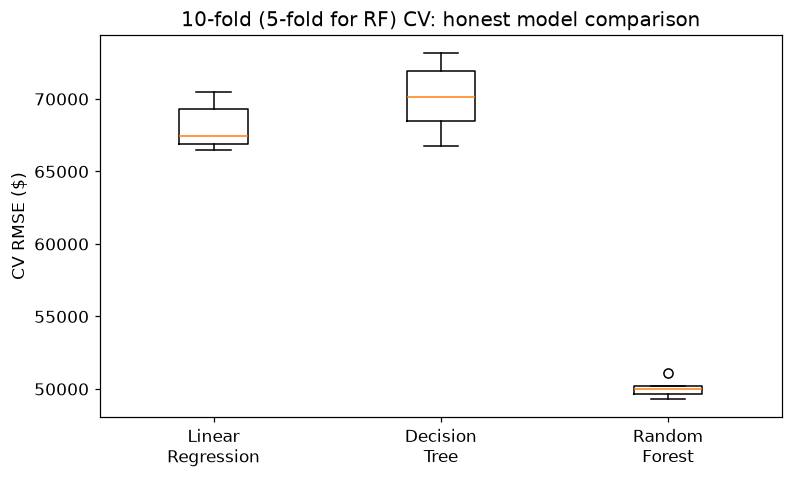

In [18]:
import pandas as pd
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot([lin_scores, tree_scores, forest_scores],
           tick_labels=['Linear\nRegression', 'Decision\nTree', 'Random\nForest'])
ax.set_ylabel('CV RMSE ($)'); ax.set_title('10-fold (5-fold for RF) CV: honest model comparison')

## 6. Tune: hyperparameters are choices, parameters are learned

In [19]:
# Grid search over a small, deliberate grid — 5-fold CV, training data only.
param_grid = [{'n_estimators': [30, 100], 'max_features': [6, 8]}]
grid = GridSearchCV(RandomForestRegressor(random_state=42, n_jobs=2),
                    param_grid, cv=5, scoring='neg_mean_squared_error',
                    return_train_score=True, n_jobs=2)
grid.fit(housing_prepared, housing_labels)
print('best params:', grid.best_params_)
print('best CV RMSE: $%.0f' % ((-grid.best_score_) ** 0.5))
cvres = grid.cv_results_
for m, p in sorted(zip(cvres['mean_test_score'], cvres['params'])):
    print('RMSE $%.0f  %s' % ((-m) ** 0.5, p))

best params: {'max_features': 6, 'n_estimators': 100}
best CV RMSE: $48913
RMSE $49622  {'max_features': 8, 'n_estimators': 30}
RMSE $49490  {'max_features': 6, 'n_estimators': 30}
RMSE $49156  {'max_features': 8, 'n_estimators': 100}
RMSE $48913  {'max_features': 6, 'n_estimators': 100}


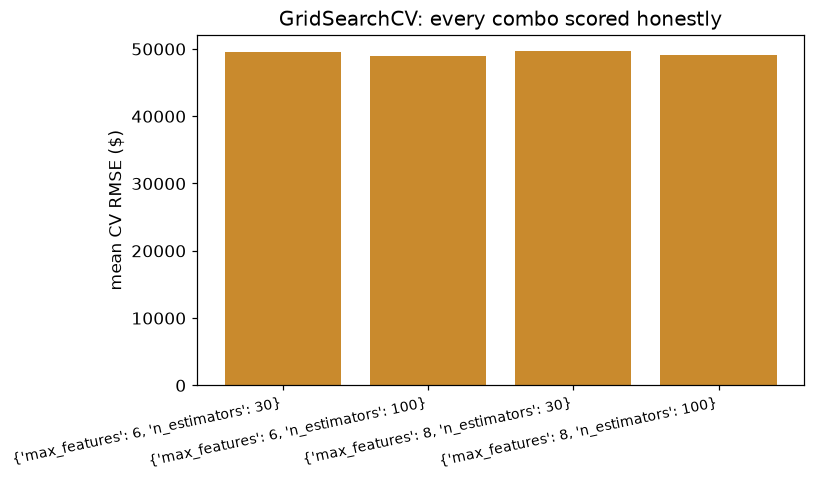

In [20]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
xs = [str(p) for p in grid.cv_results_['params']]
ys = [(-m) ** 0.5 for m in grid.cv_results_['mean_test_score']]
ax.bar(range(len(xs)), ys, color='#c98a2d')
ax.set_xticks(range(len(xs))); ax.set_xticklabels(xs, rotation=12, ha='right', fontsize=9)
ax.set_ylabel('mean CV RMSE ($)')
ax.set_title('GridSearchCV: every combo scored honestly')
plt.tight_layout()

In [21]:
# Randomized search: sample the space instead of gridding it.
param_dist = {'n_estimators': randint(20, 120), 'max_features': randint(4, 12),
              'max_depth': [None, 20, 40], 'min_samples_split': [2, 5]}
rnd = RandomizedSearchCV(RandomForestRegressor(random_state=42, n_jobs=2),
                         param_dist, n_iter=8, cv=5,
                         scoring='neg_mean_squared_error', random_state=42, n_jobs=2)
rnd.fit(housing_prepared, housing_labels)
print('best params:', rnd.best_params_)
print('best CV RMSE: $%.0f' % ((-rnd.best_score_) ** 0.5))

best params: {'max_depth': 40, 'max_features': 6, 'min_samples_split': 5, 'n_estimators': 119}
best CV RMSE: $49030


## 7. Understand the winner: importances and residuals

In [22]:
best = grid.best_estimator_
best.fit(housing_prepared, housing_labels)
importances = best.feature_importances_
names = num_cols + ['rooms_per_hhold', 'pop_per_hhold', 'bedrooms_per_room'] + \
        [f'ocean_{c}' for c in ['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN']]
top = sorted(zip(importances, names), reverse=True)[:8]
print('top features by importance:')
for imp, name in top:
    print('  %.3f  %s' % (imp, name))

top features by importance:
  0.316  median_income
  0.157  ocean_INLAND
  0.111  pop_per_hhold
  0.094  bedrooms_per_room
  0.075  longitude
  0.069  latitude
  0.054  rooms_per_hhold
  0.042  housing_median_age


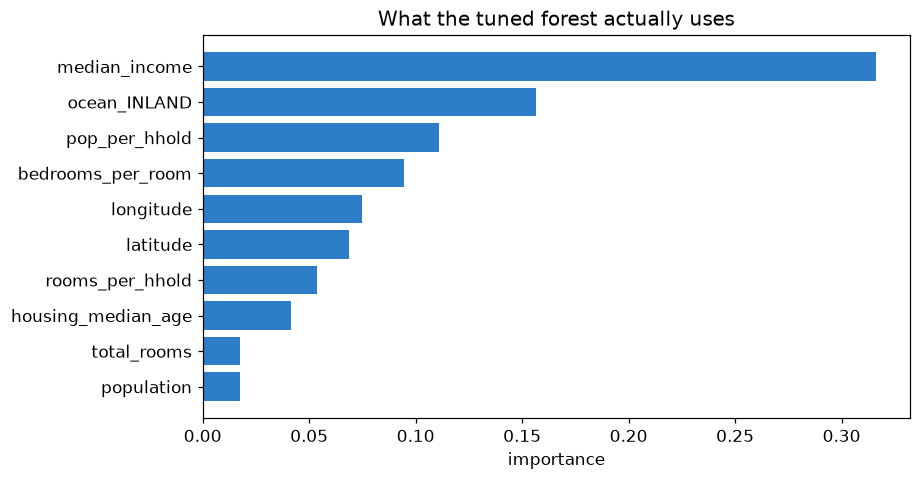

In [23]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
imps, nms = zip(*sorted(zip(best.feature_importances_, names), reverse=True)[:10])
ax.barh(nms[::-1], imps[::-1], color='#2d7dc9')
ax.set_xlabel('importance'); ax.set_title('What the tuned forest actually uses')
plt.tight_layout()

tuned model train RMSE: $18102
residual std: $18101 | 95% of errors within $35477


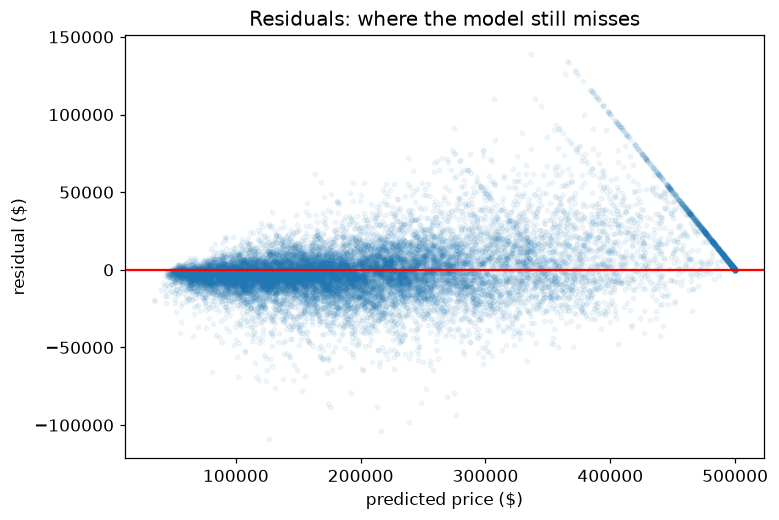

In [24]:
final_pred = best.predict(housing_prepared)
final_rmse = mean_squared_error(housing_labels, final_pred) ** 0.5
resid = housing_labels - final_pred
print('tuned model train RMSE: $%.0f' % final_rmse)
print('residual std: $%.0f | 95%% of errors within $%.0f' % (resid.std(), 1.96 * resid.std()))
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(final_pred, resid, alpha=0.06, s=8)
ax.axhline(0, color='red', lw=1.5)
ax.set_xlabel('predicted price ($)'); ax.set_ylabel('residual ($)')
ax.set_title('Residuals: where the model still misses')

## 8. The evaluation protocol: the test set stays sealed

In [25]:
# PROTOCOL (not run): the 4,128 sealed districts are scored ONCE, at the very
# end, with the frozen tuned pipeline. No tuning on test. No peeking.
# This lesson keeps them sealed, so the cell below only states the protocol.
print('FINAL EVALUATION PROTOCOL')
print('1. Freeze the tuned pipeline (preprocessing + best forest).')
print('2. Transform the 4,128 sealed districts with TRAINING statistics.')
print('3. Predict once. Compute RMSE once.')
print('4. That number is the honest estimate. If it disappoints, you do NOT')
print('   go back and tune more — that would be fitting to the test set.')

FINAL EVALUATION PROTOCOL
1. Freeze the tuned pipeline (preprocessing + best forest).
2. Transform the 4,128 sealed districts with TRAINING statistics.
3. Predict once. Compute RMSE once.
4. That number is the honest estimate. If it disappoints, you do NOT
   go back and tune more — that would be fitting to the test set.


## 9. Launch: persist, serve, monitor

In [26]:
import joblib, sys
# joblib pickles by reference: make the exec-defined transformer importable
CombinedAttributesAdder.__module__ = '__main__'
sys.modules['__main__'].CombinedAttributesAdder = CombinedAttributesAdder
joblib.dump(best, 'housing_model.pkl')
joblib.dump(full_pipeline, 'housing_preprocessing.pkl')
print('saved: housing_model.pkl + housing_preprocessing.pkl')
# One new district, straight through the frozen pipeline:
sample = housing.iloc[[0]]
price = best.predict(full_pipeline.transform(sample))[0]
print('sample district predicted price: $%.0f' % price)

saved: housing_model.pkl + housing_preprocessing.pkl
sample district predicted price: $411176


## Launch checklist
- Freeze preprocessing + model as versioned artifacts.
- Validate inputs at serving time (ranges learned from TRAIN).
- Monitor: prediction distribution drift, feature drift, business metrics.
- Retrain on a schedule with fresh data — never on the sealed test set.
- Log everything: data snapshot id, code version, hyperparameters.

That is the whole arc: frame, explore, clean, scale, pipeline, select, tune, evaluate once, launch, monitor. The notebook file itself is yours to download and rerun.